## EDA Student Performance Indicator

### 1) Problem statement
- This project understands how the student's performance (test scores) is affected by other variables such as Gender, Ethnicity, Parental level of education, Lunch and Test preparation course.


### 2) Data Collection
- Dataset Source - https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?datasetId=74977
- The data consists of 8 column and 1000 rows.

### 3) Dataset Information
- gender : sex of students  -> (Male/female)
- race/ethnicity : ethnicity of students -> (Group A, B,C, D,E)
- parental level of education : parents' final education ->(bachelor's degree,some college,master's degree,associate's degree,high school)
- lunch : having lunch before test (standard or free/reduced)
- test preparation course : complete or not complete before test
- math score
- reading score
- writing score

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r'F:\EDA\student.csv')

In [3]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race_ethnicity               1000 non-null   object
 2   parental_level_of_education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test_preparation_course      1000 non-null   object
 5   math_score                   1000 non-null   int64 
 6   reading_score                1000 non-null   int64 
 7   writing_score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [5]:
df.isna().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

In [6]:
df.isnull().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

In [8]:
df.duplicated().sum()

0

In [9]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [16]:
mean = df['math_score'].mean()
print(mean)

66.089


<Axes: xlabel='math_score', ylabel='Count'>

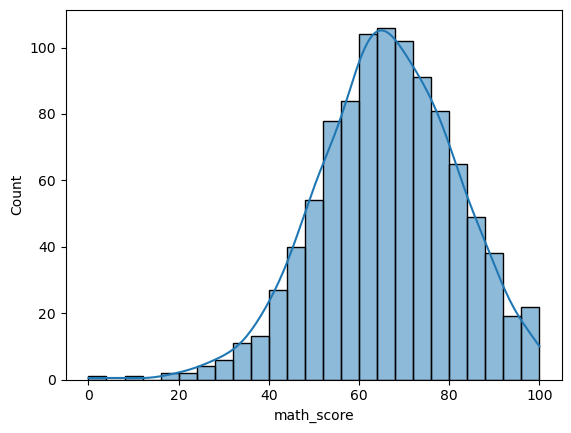

In [ ]:
sns.histplot(df['math_score'],kde=True)

In [29]:
df['math_score'] = df['math_score'].replace(0, mean) 

In [32]:
df['math_score'].min()

8.0

In [33]:
df.describe()

,math_score,reading_score,writing_score
count,1000.000000,1000.000000,1000.000000
mean,66.155089,69.169000,68.054000
std,15.018072,14.600192,15.195657
min,8.000000,17.000000,10.000000
25%,57.000000,59.000000,57.750000
50%,66.000000,70.000000,69.000000
75%,77.000000,79.000000,79.000000
max,100.000000,100.000000,100.000000


In [36]:
df.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score'],
      dtype='object')

In [47]:
## Number of unique values in each columns

df['gender'].unique()

array(['female', 'male'], dtype=object)

In [48]:
df['lunch'].unique()

array(['standard', 'free/reduced'], dtype=object)

In [49]:
df['race_ethnicity'].unique()

array(['group B', 'group C', 'group A', 'group D', 'group E'],
      dtype=object)

In [46]:
df['parental_level_of_education'].unique()

array(["bachelor's degree", 'some college', "master's degree",
       "associate's degree", 'high school', 'some high school'],
      dtype=object)

In [50]:
df['total_score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['Average'] = df['total_score'] / 3

In [52]:
df[['total_score','Average']]

,total_score,Average
0,218.0,72.666667
1,247.0,82.333333
2,278.0,92.666667
3,148.0,49.333333
4,229.0,76.333333
...,...,...
995,282.0,94.000000
996,172.0,57.333333
997,195.0,65.000000
998,223.0,74.333333


<Axes: xlabel='Average', ylabel='Count'>

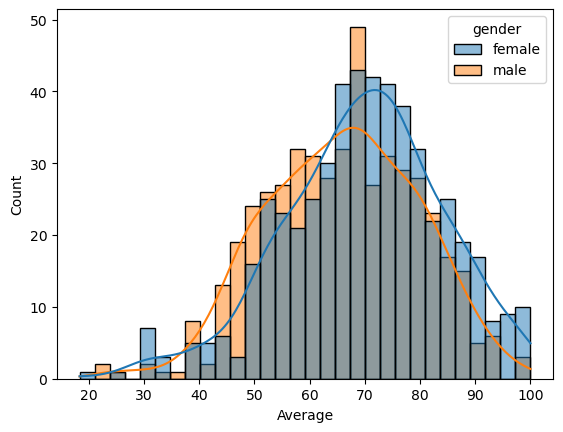

In [57]:
sns.histplot(data=df,x=df['Average'],bins=30,kde=True,hue='gender')

In [60]:
df['Average'].groupby(df['gender']).median()

gender
female    70.333333
male      66.333333
Name: Average, dtype: float64

From the above we can come to know that female students performs well

<Axes: xlabel='gender', ylabel='Average'>

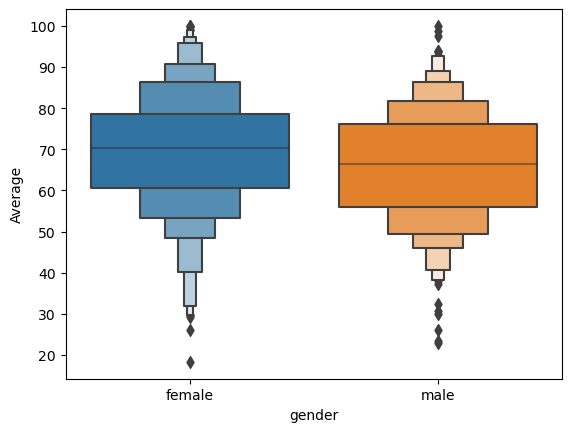

In [67]:
sns.boxenplot(x='gender', y='Average', data=df, showfliers=True)

C:\Users\HP\AppData\Local\Temp\ipykernel_2524\1929952164.py:2: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(141)
C:\Users\HP\AppData\Local\Temp\ipykernel_2524\1929952164.py:4: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(142)
C:\Users\HP\AppData\Local\Temp\ipykernel_2524\1929952164.py:6: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(143)


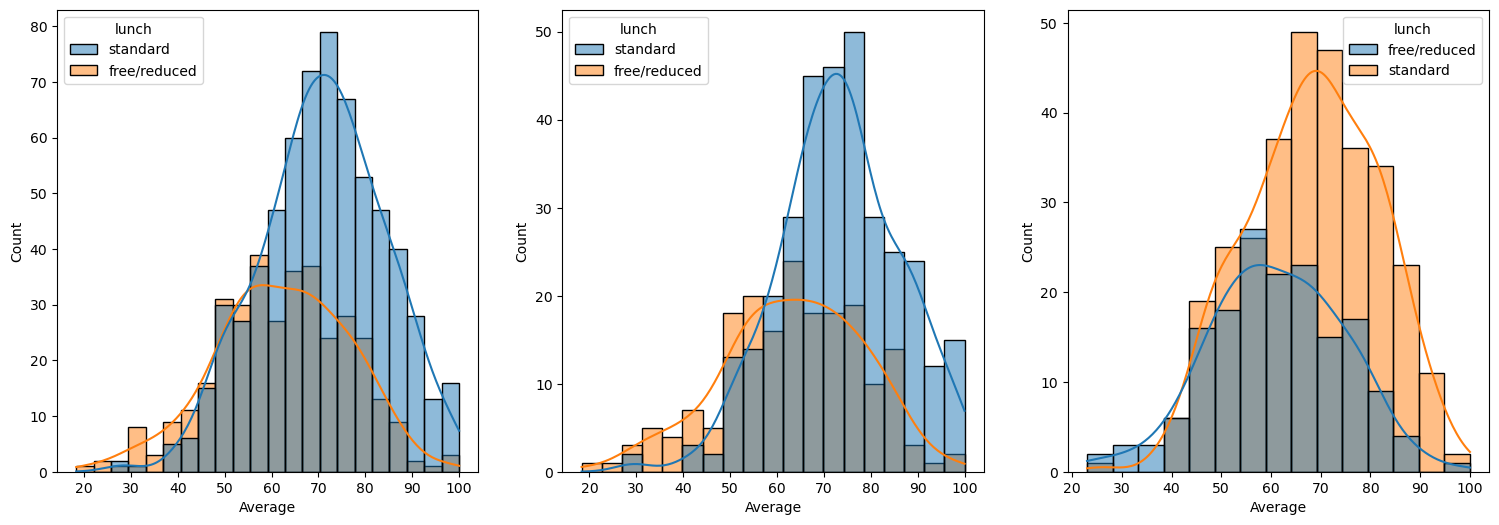

In [71]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(141)
sns.histplot(data=df,x=df['Average'],kde=True,hue='lunch')
plt.subplot(142)
sns.histplot(data=df[df.gender=='female'],x=df['Average'],kde=True,hue='lunch')
plt.subplot(143)
sns.histplot(data=df[df.gender=='male'],x=df['Average'],kde=True,hue='lunch')
plt.show()

In [75]:
df['Average'].groupby(df['lunch']).mean()

lunch
free/reduced    62.261116
standard        70.837209
Name: Average, dtype: float64

In [81]:
# Mean of Average for female students overall
female_df = df[df['gender'] == 'female']
female_mean = female_df['Average'].mean()
print("Overall female mean:", female_mean)

# Mean of Average for female students by lunch type
female_means_by_lunch = female_df.groupby('lunch')['Average'].mean()
print("Female mean by lunch type:")
print(female_means_by_lunch)


Overall female mean: 69.61202638352638
Female mean by lunch type:
lunch
free/reduced    63.331727
standard        73.219858
Name: Average, dtype: float64


In [84]:
# Mean of Average for female students overall
male_df = df[df['gender'] == 'male']
male_mean = male_df['Average'].mean()
print("Overall female mean:", female_mean)

# Mean of Average for female students by lunch type
male_means_by_lunch = male_df.groupby('lunch')['Average'].mean()
print("male mean by lunch type:")
print(male_means_by_lunch)


Overall female mean: 69.61202638352638
male mean by lunch type:
lunch
free/reduced    61.042169
standard        68.356540
Name: Average, dtype: float64


from the above we can conclude that standard luch hepls the student performs well in exams
- Standard lunch helps perform well in exams be it a male of female


C:\Users\HP\AppData\Local\Temp\ipykernel_2524\564504710.py:2: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(141)
C:\Users\HP\AppData\Local\Temp\ipykernel_2524\564504710.py:4: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(142)
C:\Users\HP\AppData\Local\Temp\ipykernel_2524\564504710.py:6: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(143)


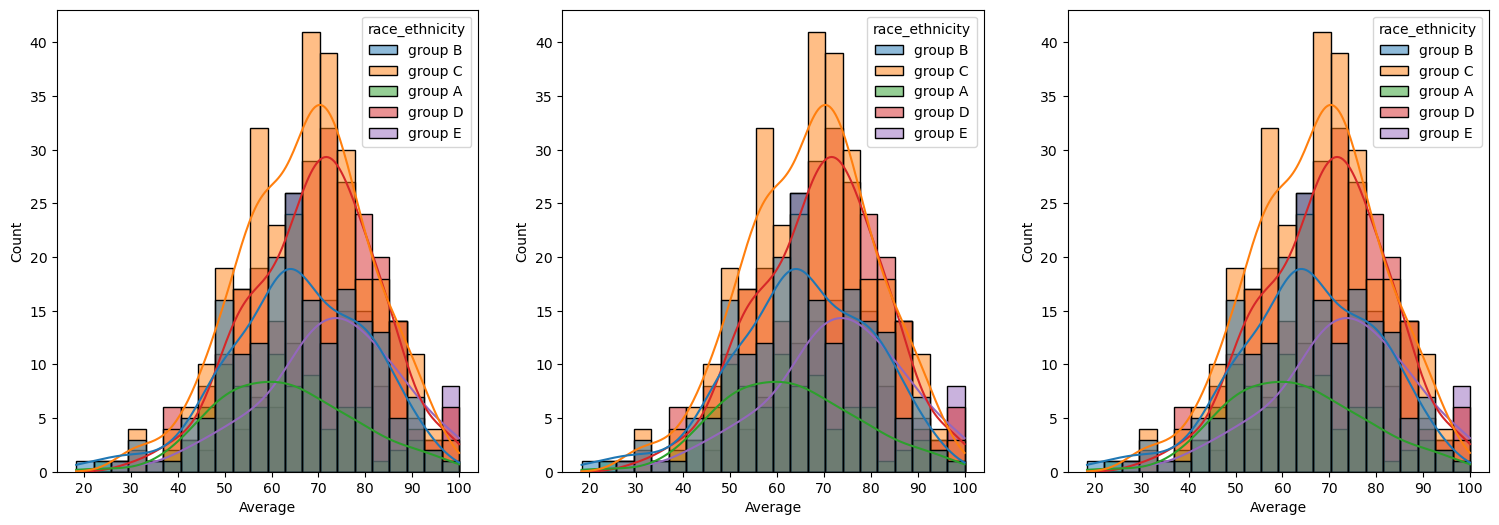

In [86]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(141)
sns.histplot(data=df,x=df['Average'],kde=True,hue='race_ethnicity')
plt.subplot(142)
sns.histplot(data=df[df.gender=='female'],x=df['Average'],kde=True,hue=df['race_ethnicity'])
plt.subplot(143)
sns.histplot(data=df[df.gender=='male'],x=df['Average'],kde=True,hue=df['race_ethnicity'])
plt.show()

#####  Insights
- Students of group A and group B tends to perform poorly in exam.
- Students of group A and group B tends to perform poorly in exam irrespective of whether they are male or female

In [88]:
df.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score', 'total_score', 'Average'],
      dtype='object')

In [89]:
df.dtypes

gender                          object
race_ethnicity                  object
parental_level_of_education     object
lunch                           object
test_preparation_course         object
math_score                     float64
reading_score                    int64
writing_score                    int64
total_score                    float64
Average                        float64
dtype: object

In [93]:
df1 = df[['reading_score','writing_score','total_score','math_score','Average']].corr()

<Axes: >

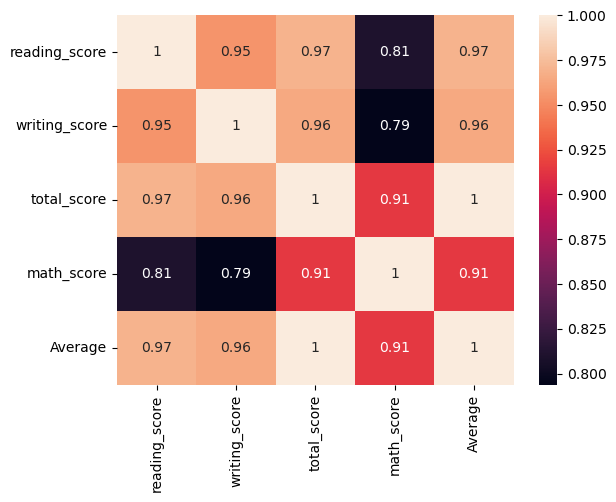

In [94]:
sns.heatmap(df1,annot=True)